# Classificador Distância Mínima ao Centroide — versão robusta a outliers

*Implementação em numpy · base original (sem pré-processamento)*

O centroide de cada classe é substituído pela **mediana** de cada atributo, que não é afetada por valores extremos, e a distância euclidiana pela distância de **Manhattan** (L1). A mediana é justamente o ponto que minimiza a soma das distâncias L1 às amostras da classe:

$$\hat{y}(\mathbf{x}) = \arg\min_i \|\mathbf{x} - \tilde{\mathbf{m}}_i\|_1, \qquad \tilde{\mathbf{m}}_i = \text{mediana das amostras da classe } i$$

Protocolo (OBS 1–4 do enunciado): 100 rodadas treino-teste independentes e estratificadas para cada separação 20/80, 30/70, 50/50, 70/30 e 80/20.

## Dados

In [1]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "1"  # antes do numpy: evita falta de memória do OpenBLAS no Windows

import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
from avaliacao import (SPLITS, carregar, avaliar, estatisticas, matrizes_confusao, grafico_splits,
                       por_classe, grafico_por_classe, resumo, salvar)

pd.set_option("display.max_rows", 200)

X, y, classes = carregar(processada=False)
print(f"{len(y)} instâncias | {X.shape[1]} atributos | {len(classes)} classes: {list(classes)}")

5456 instâncias | 4 atributos | 4 classes: ['Move-Forward', 'Sharp-Right-Turn', 'Slight-Left-Turn', 'Slight-Right-Turn']


## Modelo

In [2]:
class DistanciaMinimaCentroideRobusto:
    def fit(self, X, y):
        self.classes_ = np.unique(y)
        self.centroides_ = np.array([np.median(X[y == c], axis=0) for c in self.classes_])  # mediana por classe
        return self

    def predict(self, X):
        d = np.abs(X[:, None, :] - self.centroides_[None]).sum(axis=2)  # distância de Manhattan (L1)
        return self.classes_[d.argmin(axis=1)]


MODELOS = {"DMC robusto": DistanciaMinimaCentroideRobusto()}

## Execução
100 rodadas × 5 separações. Em cada rodada, todos os modelos usam a mesma divisão treino/teste.

In [3]:
res, confusoes = avaliar(MODELOS, X, y, classes)
salvar(res, "classification", "distancia_minima_centroide_robust")

## OBS 1 e 2 — Estatísticas de acurácia e tempos de treinamento/teste (ms)

In [4]:
estatisticas(res).round(4)

,,média,desvio,máxima,mínima,mediana,t_treino_ms,t_teste_ms
split,modelo,,,,,,,
20/80,DMC robusto,0.7599,0.0165,0.7952,0.7244,0.7622,0.4912,0.8599
30/70,DMC robusto,0.7585,0.0190,0.7926,0.7183,0.7629,0.7568,1.0324
50/50,DMC robusto,0.7560,0.0161,0.7900,0.7263,0.7558,0.8973,0.6086
70/30,DMC robusto,0.7564,0.0157,0.7903,0.7207,0.7576,0.8937,0.3455
80/20,DMC robusto,0.7556,0.0153,0.7883,0.7122,0.7571,1.0819,0.3069


## OBS 2 — Matrizes de confusão da melhor e da pior rodada

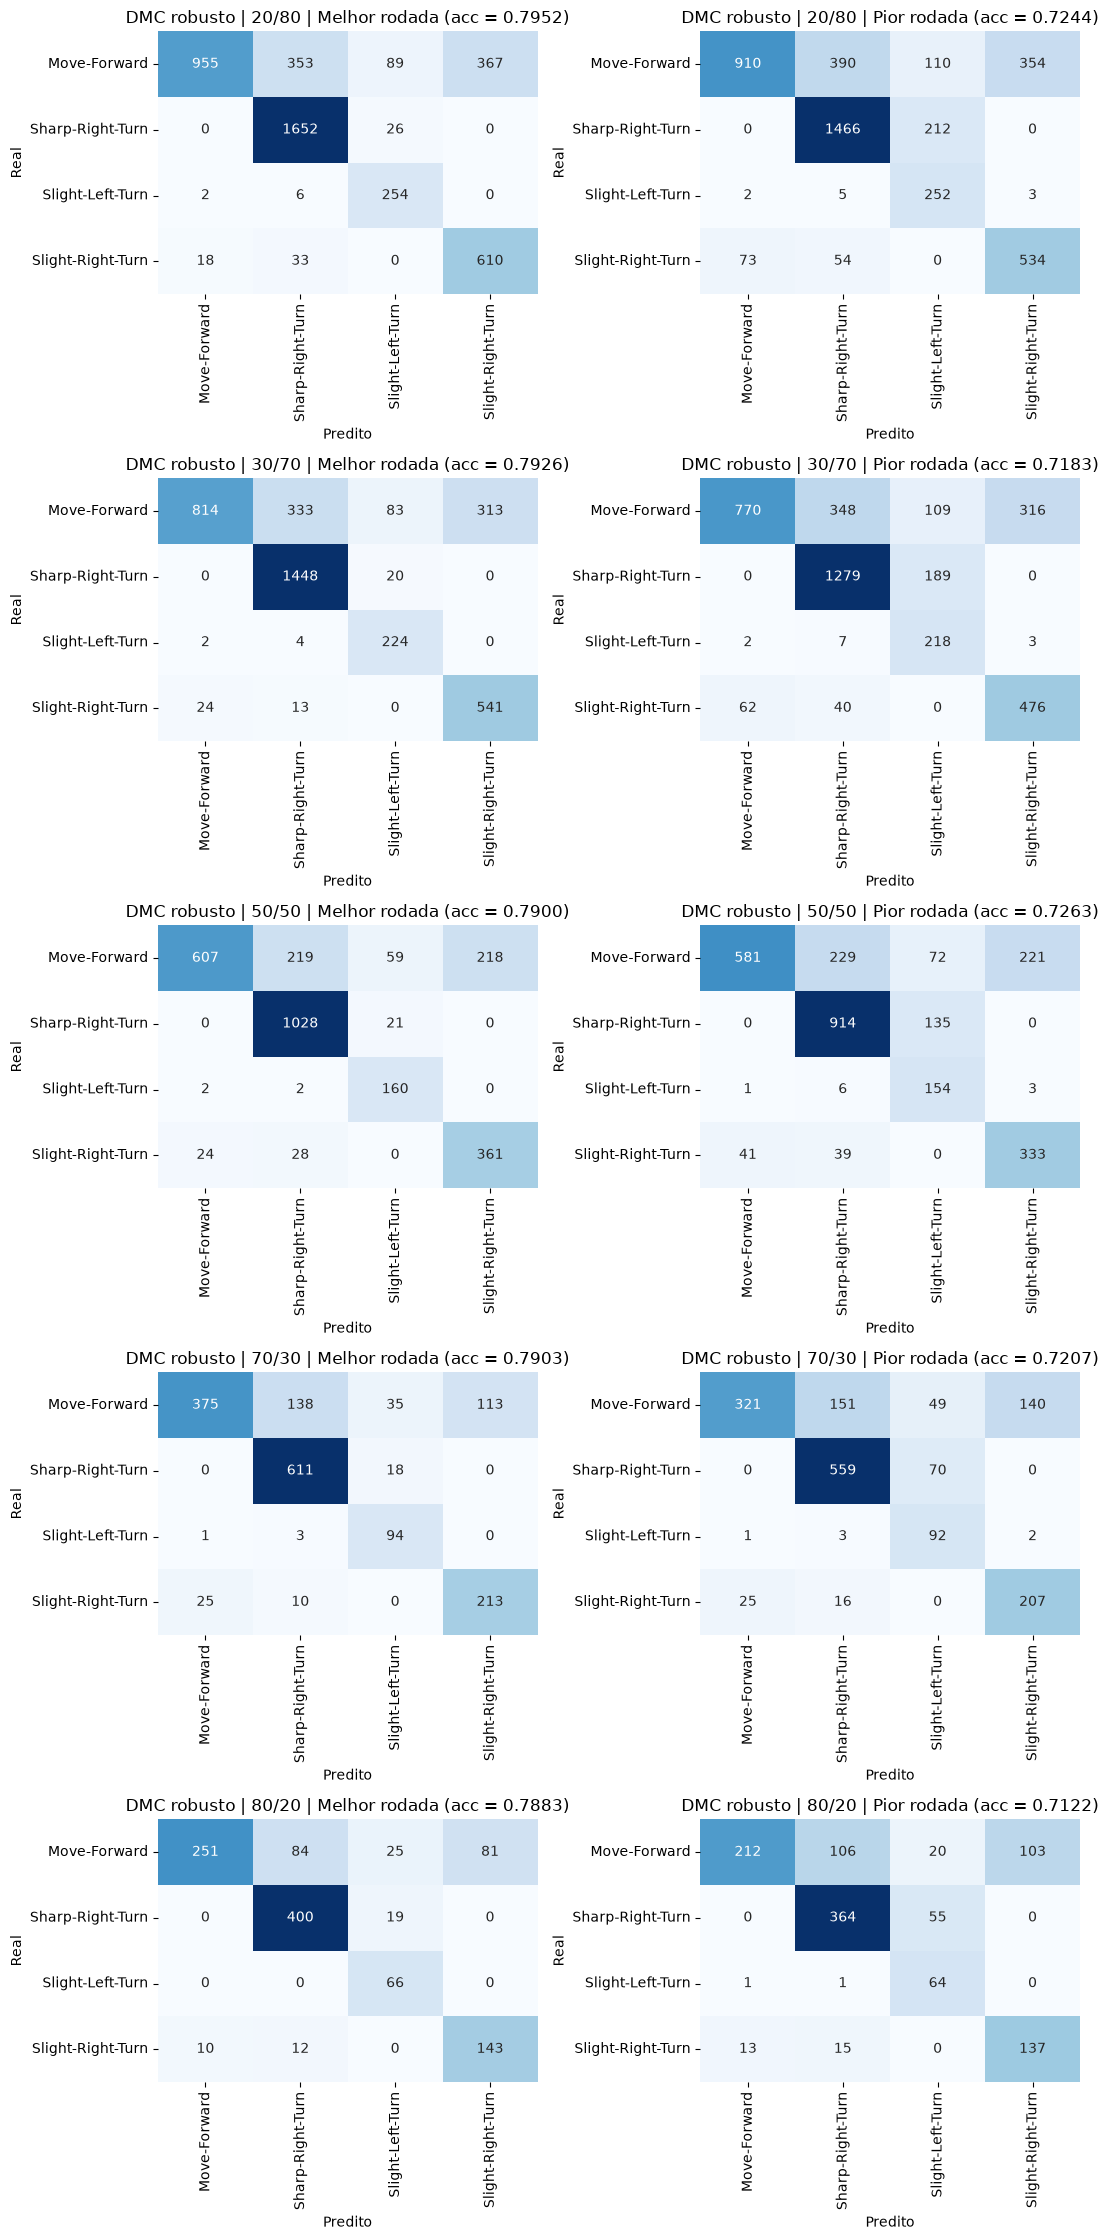

In [5]:
matrizes_confusao(res, confusoes, classes, splits=SPLITS)

## OBS 3 — Efeito da separação treino/teste

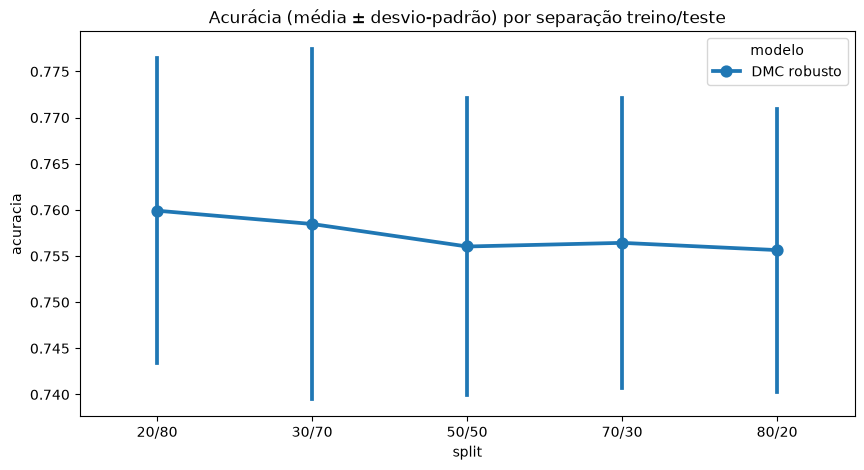

In [6]:
grafico_splits(res)

## OBS 4 — Desempenho por classe (taxa de acerto de cada classe)

In [7]:
por_classe(res, classes).round(4)

média  desvio  máxima  mínima  mediana
classe            split modelo                                              
Move-Forward      20/80 DMC robusto  0.5366  0.0158  0.5777  0.5034   0.5334
                  30/70 DMC robusto  0.5346  0.0143  0.5671  0.4990   0.5343
                  50/50 DMC robusto  0.5340  0.0118  0.5621  0.4995   0.5358
                  70/30 DMC robusto  0.5326  0.0170  0.5749  0.4826   0.5340
                  80/20 DMC robusto  0.5285  0.0223  0.5692  0.4671   0.5283
Sharp-Right-Turn  20/80 DMC robusto  0.9279  0.0417  0.9869  0.8665   0.9428
                  30/70 DMC robusto  0.9274  0.0417  0.9871  0.8651   0.9380
                  50/50 DMC robusto  0.9212  0.0391  0.9800  0.8599   0.9271
                  70/30 DMC robusto  0.9247  0.0347  0.9809  0.8617   0.9285
                  80/20 DMC robusto  0.9274  0.0311  0.9833  0.8640   0.9284
Slight-Left-Turn  20/80 DMC robusto  0.9606  0.0072  0.9809  0.9466   0.9599
                  30/70 DMC robusto  0.9615  0.0086  0.9826  0.9435   0.9609
                  50/50 DMC robusto  0.9606  0.0117  0.9878  0.9329   0.9604
                  70/30 DMC robusto  0.9591  0.0166  1.0000  0.8980   0.9592
                  80/20 DMC robusto  0.9576  0.0200  1.0000  0.9091   0.9545
Slight-Right-Turn 20/80 DMC robusto  0.8500  0.0389  0.9395  0.7610   0.8510
                  30/70 DMC robusto  0.8464  0.0351  0.9516  0.7682   0.8478
                  50/50 DMC robusto  0.8483  0.0305  0.9104  0.7821   0.8475
                  70/30 DMC robusto  0.8460  0.0262  0.9274  0.7742   0.8468
                  80/20 DMC robusto  0.8458  0.0308  0.9394  0.7758   0.8485

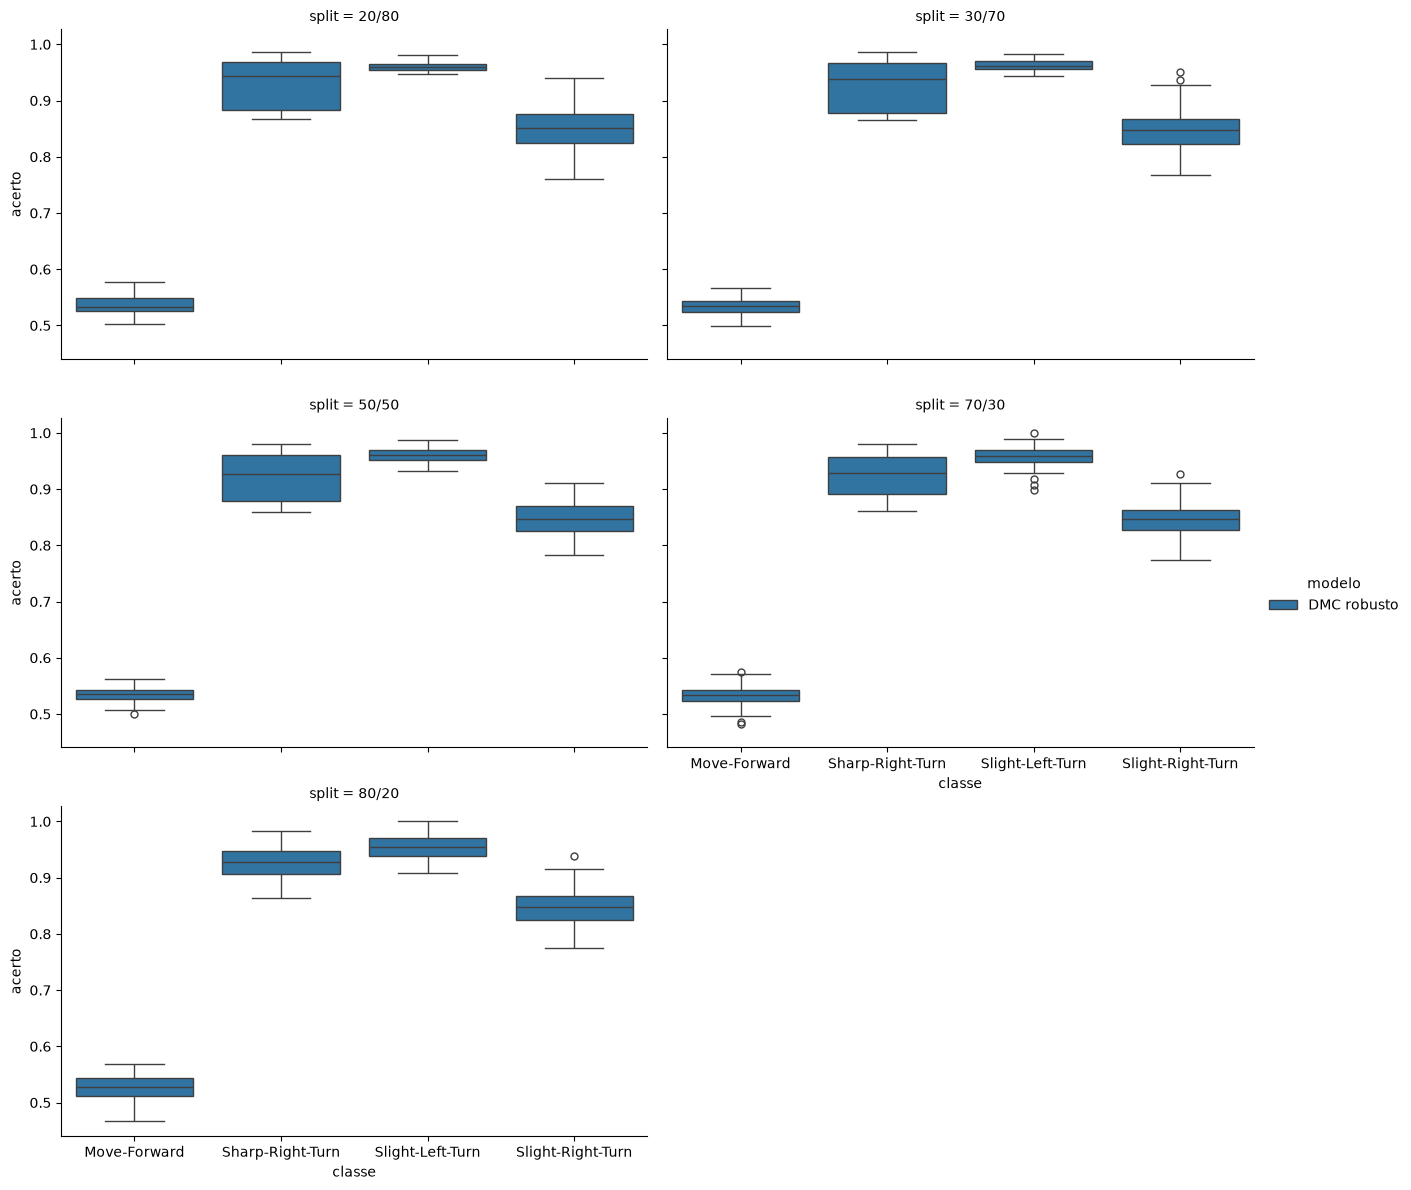

In [8]:
grafico_por_classe(res, classes)

## Resumo dos resultados

In [9]:
resumo(res, classes)

Melhor configuração: DMC robusto com split 20/80 -> acurácia média 0.7599

Tempo médio por rodada (ms):
  DMC robusto: treino 0.824 | teste 0.631

Efeito do split (acurácia média 20/80 -> 80/20):
  DMC robusto: 0.7599 -> 0.7556 (-0.0043)

Taxa de acerto média por classe (todas as rodadas):
  Move-Forward: 0.5333
  Slight-Right-Turn: 0.8473
  Sharp-Right-Turn: 0.9257
  Slight-Left-Turn: 0.9599
Classe mais fácil: Slight-Left-Turn | mais difícil: Move-Forward
